# Binary Classification for healthy/unhealthy plant species

AN2DL homework 1 (Politecnico di Milano, 2023), team RedstoneRookies: Axel Friberg Hagen, Vegard Sjåvik, Lasse Uttian.
We classify 96x96 plant images as healthy/unhealthy, going from a LeNet baseline to a fine-tuned MobileNetV2. Written for Colab, so the Drive paths need changing to run it elsewhere.

In [1]:
from google.colab import drive
drive.mount('/gdrive')
%cd /gdrive/My Drive/RedstoneRookies

Mounted at /gdrive
[Errno 2] No such file or directory: '/gdrive/My Drive/RedstoneRookies'
/content


## Importing libraries

In [2]:

# Fix randomness and hide warnings
seed = 42

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['PYTHONHASHSEED'] = str(seed)
os.environ['MPLCONFIGDIR'] = os.getcwd()+'/configs/'

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

import numpy as np
np.random.seed(seed)

import logging

import random
random.seed(seed)

# Import tensorflow
import tensorflow as tf
from tensorflow import keras as tfk
from tensorflow.keras import layers as tfkl
tf.autograph.set_verbosity(0)
tf.get_logger().setLevel(logging.ERROR)
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)
tf.random.set_seed(seed)
tf.compat.v1.set_random_seed(seed)
print(tf.__version__)

# Import other libraries
import cv2
import datetime
from tensorflow.keras.applications.mobilenet import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import seaborn as sns
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

2.14.0


## Loading data

In [3]:
np_array = np.load("/gdrive/MyDrive/Colab Notebooks/RedstoneRookies/public_data.npz", allow_pickle=True)

In [4]:
X_raw = np_array["data"]/255 # normalize data from 0 to 1
y_raw = np_array["labels"]

In [5]:
print(f"Data shape {X_raw.shape}")
print(f"Label shape {y_raw.shape}")

Data shape (5200, 96, 96, 3)
Label shape (5200,)


## Data exploration


### Looking into a set of images
First we would like to see example of some of the images in the dataset

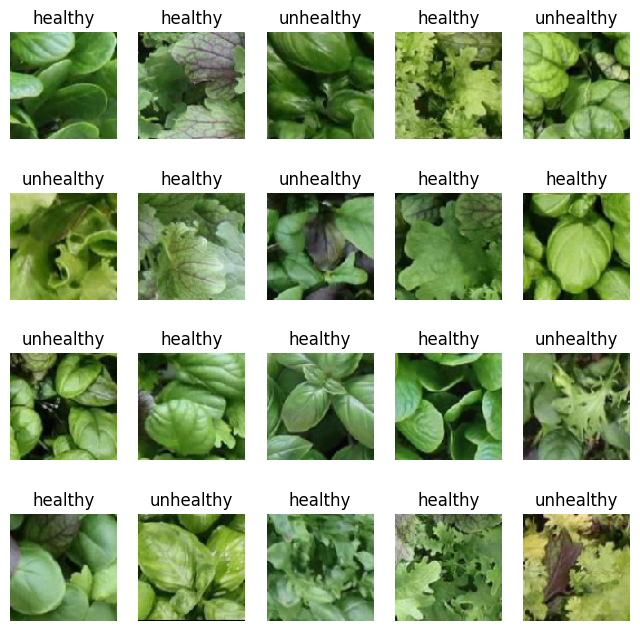

In [6]:
# Generate random indices to select 20 images to see what healthy/unhealthy looks like (I can't tell the difference tbh)
random_indices = np.random.choice(X_raw.shape[0], size=20, replace=False)

# Plot the selected images
plt.figure(figsize=(8, 8))
for i, idx in enumerate(random_indices, 1):
    plt.subplot(4, 5, i)
    plt.imshow(X_raw[idx])
    plt.title(y_raw[idx])
    plt.axis('off')

plt.show()

### Distribution of labels
Then we would like to see the distribution of healthy/unhealthy labels in the dataset

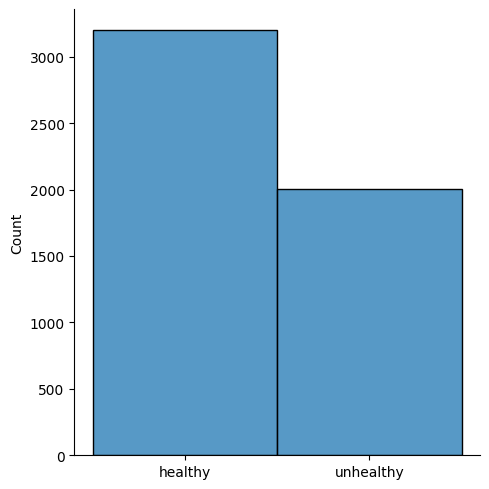

In [7]:
sns.displot(data=y_raw)

As we can see there is about 66% healthy plants and 33% unhealthy ones. This should be addressed in training to avoid the model leaning towards only predicting healthy plants

## Data cleaning

### Removing shrek and trololo from dataset
During data exploration, some examples of bad data were found. These were found on the indices 840 and 1759. These will be removed along side any duplicates of these

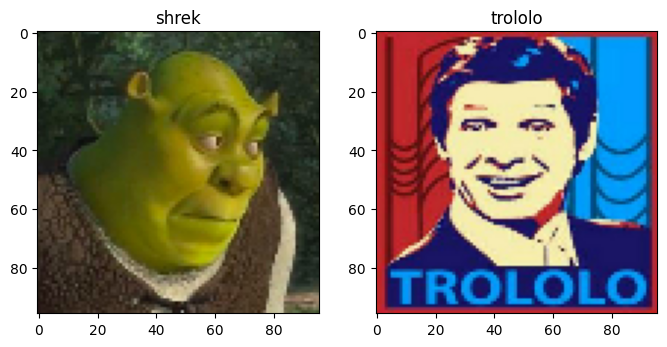

In [8]:
# Quantifying the outliers
shrek = X_raw[840] # Random shrek image found
trololo = X_raw[1759] # Random trololo image found

# plot of shrek
fig = plt.figure(figsize=(8, 8))
fig.add_subplot(1, 2, 1)
plt.imshow(shrek)
plt.title("shrek")

# plot of trololo
fig.add_subplot(1, 2, 2)
plt.imshow(trololo)
plt.title("trololo")
plt.show()

In [ ]:
N = X_raw.shape[0]
toBeRemoved = np.zeros(N)
tol = 1.e-5 # tolerance of similarity due to potential rounding issues
for i in range(1,N):
  # "flags" index of all images that are similar in 1-norm to shrek or trololo
  toBeRemoved[i] = np.sum(abs(X_raw[i] - shrek)) < tol or np.sum(abs(X_raw[i] - trololo)) < tol

print(f'{np.sum(toBeRemoved)} images detected as trololo or shrek, equaling about {round(np.mean(toBeRemoved)*100,2)}% of dataset')

In [10]:
# Removing images of shrek or trololo
X = np.delete(X_raw, np.where(toBeRemoved == 1), axis=0)
y = np.delete(y_raw, np.where(toBeRemoved == 1))

By curiosity we check the distribution of labels in the "faulty" data. Interestingly we observe shrek to be only unhealthy, and mr. trololo to be only healthy.

In [11]:
# Comparing example photos of shrek and trololo to all images and "flagging" ones that are very similar in 1-norm
shreks = np.zeros(N)
for i in range(1,N):
  shreks[i] = np.sum(abs(X_raw[i] - shrek)) < tol

trololos = np.zeros(N)
for i in range(1,N):
  trololos[i] = np.sum(abs(X_raw[i] - trololo)) < tol

In [12]:
print(f'{np.mean(y_raw[np.where(shreks == 1)]=="healthy")*100}% healthy labels for shrek images')
print(f'{np.mean(y_raw[np.where(trololos == 1)]=="healthy")*100}% healthy labels for trololo images')

0.0% healthy labels for shrek images
100.0% healthy labels for trololo images


### Finding and removing duplicates to prevent overfitting
When recieving an unknown dataset like this, it is always good practice to check it thoroughly. A good place to start searching is by checking for duplicates. We use a hashing algorithm of the images and compare hashes as it is much faster than comparing pixel for pixel. We use this algorithm on top of the shrek/trololo removal algorithm (even though this would technically remove all duplicates of the shrololo-algorithm also) in order to gain inference on the different types of data we remove (and also because this algorithm would leave 1 shrololo image)

In [13]:
# finding duplicates by hashing all images and then comparing hashes
def compute_hashes(images):
    hashes = {}
    for i, img in enumerate(images):
        # Create a hash of the image, you can use any hash function here
        img_hash = hash(img.tobytes())
        if img_hash in hashes:
            hashes[img_hash].append(i)
        else:
            hashes[img_hash] = [i]
    return hashes

def find_duplicate_hashes(hashes):
    duplicates = []
    for img_list in hashes.values():
        if len(img_list) > 1:
            duplicates.append(img_list)
    return duplicates

hashes = compute_hashes(X)
duplicates = find_duplicate_hashes(hashes)

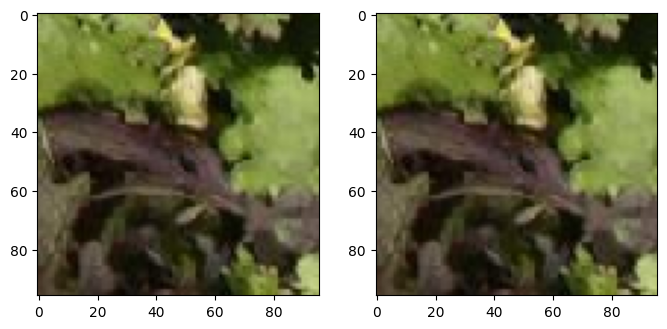

In [14]:
# Look at some random images marked as duplicates to check algorithm works
dupes = np.array(duplicates[np.random.randint(len(duplicates))]) # look at duplicates
fig = plt.figure(figsize=(8, 8))
for i, im in enumerate(dupes):
    img = X[im]
    fig.add_subplot(1, dupes.size, i+1)
    plt.imshow(img)
plt.show()

In [15]:
duplicateIndices = np.array([],dtype=int)
for duplicate in duplicates:
  dup = np.array(duplicate)[1:] # only removes the duplicates and not all indices
  duplicateIndices = np.concatenate((duplicateIndices,dup))

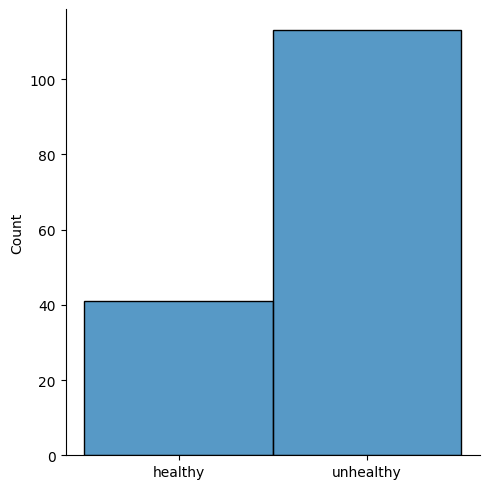

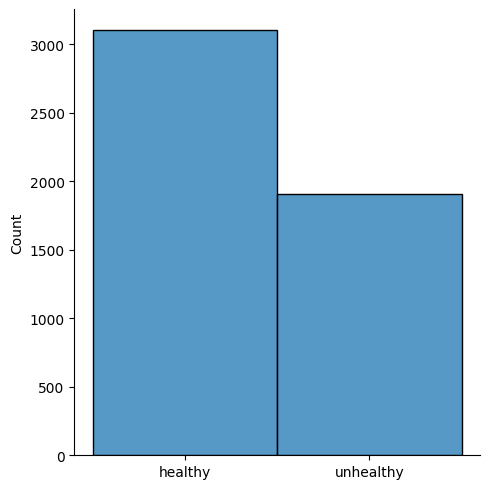

In [16]:
# Look at distribution of duplicates
sns.displot(y[duplicateIndices])
sns.displot(y)

In [17]:
print(np.mean(y=="healthy"))
print(np.mean(y[duplicateIndices]=="healthy"))

0.6197042366107114
0.2662337662337662


We can see that the duplicate images consists of 27% healthy labels, while in the rest of the data the distribution is 62% healthy labels. Removing the duplicates should help prevent overfitting, although the sparse class is unhealthy, and the duplicates mostly belong to this class, so dataset is even more unbalanced.

In [18]:
X_final = np.delete(X, duplicateIndices, axis=0)
y_final = np.delete(y, duplicateIndices)

print(X_final.shape) # Should be consistant in the first channel
print(y_final.shape)

(4850, 96, 96, 3)
(4850,)


Convert labels to 0 (unhealthy) and 1 (healthy) for feeding the network.

## Data processing
To make the data work for a neural network we need to discretize labels. This is done by making unhealthy a 0 and healthy a 1

In [19]:
# Converts labels to 0 and 1
labels = {"unhealthy": 0, "healthy": 1}
y_encoded = np.vectorize(labels.get)(y_final)

## Train/test/validation splitting

After processing and preparing the data, we split the data into train, validation and test sets. To ensure that the different sets has the same distribution.



In [20]:
# First split into test and train
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_final,
    y_encoded,
    test_size = 0.2,
    random_state=seed,
    stratify=y_encoded # stratify to have even distribution of classes in the splits
)

# Further split training set into training and validation
X_train, X_validation, y_train, y_validation = train_test_split(
    X_train_val,
    y_train_val,
    test_size = len(X_test),
    random_state=seed,
    stratify=y_train_val
)

In [21]:
print(np.mean(y_test==1))
print(np.mean(y_validation==1))
print(np.mean(y_train==1)) # Same distribution, though pretty unbalanced with mostly healthy plants

0.6309278350515464
0.6309278350515464
0.6309278350515464


As we can see, the distribution is the same in all the datasets

## Expanding the dimensions of the labels to fit the model
To make the data compatible with the neural network we need to expand the dimensions of the labels from (x,) to (x,1)

In [22]:
# Expand the labels dimension moving from (x,) to (x, 1), with x cardinality
if y_train.ndim == 1: # to prevent further expansion than 1 by accidently running cell multiple times
  y_train = np.expand_dims(y_train, axis=-1)
  y_test = np.expand_dims(y_test, axis=-1)
  y_validation = np.expand_dims(y_validation, axis=-1)

print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")
print(f"y_validation shape: {y_validation.shape}")

y_train shape: (2910, 1)
y_test shape: (970, 1)
y_validation shape: (970, 1)


## Define key model parameters

In [23]:
input_shape = X_train.shape[1:]  # Input shape for the model (size of image, 96x96x3)
output_shape = y_train.shape[1]  # Output shape for the model (1 since binary classification)
batch_size = 128                 # Batch size for training
epochs = 200                     # Number of training epochs

## Image augmentation
Sicne we have images of plants with different markings showing if the plant is healthy/unhealthy it is benefitial to augment the images to increase the size of training examples. The following augmentations are deemed to be OK as there would be no difference in classification based on these:
- Translation
- Flip
- Rotation
- Contrast
- Brightness

In [24]:
def build_image_augmentation_layer():
   ## Layer for image augmentation
  return tf.keras.Sequential([
      tfkl.RandomBrightness(0.2, value_range=(0,1)),
      tfkl.RandomTranslation(0.2,0.2),
      tfkl.RandomRotation(0.2),
      tfkl.RandomContrast(0.2),
      tfkl.RandomFlip()
  ], name='Image_Augmentation')

## Addressing class imbalance
To address class imbalance we add input the weights for each class during training. To do this we use sklearn's inbuilt functions.

In [25]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(class_weight='balanced',
                                                 classes=[0,1],
                                                 y=y_train.flatten().tolist())

class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

## Building a simple LeNet model
At first we will create a simple LeNet model to see how it performs. Most certaintly it will be too simple for our task

In [26]:
def build_LeNet(input_shape, seed=seed):
    tf.random.set_seed(seed)

    # Create an input layer
    inputs = tfk.Input(shape=input_shape)

    preprocessing = build_image_augmentation_layer()(inputs)

    conv1 = tfkl.Conv2D(
        filters=6,
        kernel_size=(5,5),
        padding='same',
        activation='tanh',
        name='conv1'
    )(preprocessing)

    pool1 = tfkl.MaxPooling2D(
        pool_size=(2,2),
        name='mp1'
    )(conv1)

    conv2 = tfkl.Conv2D(
        filters=16,
        kernel_size=(5,5),
        padding='valid',
        activation='tanh',
        name='conv2'
    )(pool1)

    pool2 = tfkl.MaxPooling2D(
        pool_size =(2,2),
        name='mp2'
    )(conv2)

    flattening_layer=tfkl.Flatten(
        name='flatten'
    )(pool2)

    classifier_layer=tfkl.Dense(
        units=120,
        activation='tanh',
        name='dense1'
    )(flattening_layer)

    classifier_layer = tfkl.Dense(
        units=84,
        activation='tanh',
        name='dense2'
    )(classifier_layer)

    output_layer = tfkl.Dense(
        units=1,
        activation='sigmoid',
        name='Output'
    )(classifier_layer)

    # Connect input and output through the Model class
    model = tfk.Model(inputs=inputs, outputs=output_layer, name='LeNet')

    # Compile the model
    model.compile(loss=tfk.losses.BinaryCrossentropy(), optimizer=tfk.optimizers.Adam(), metrics=[tf.keras.metrics.AUC(), 'accuracy'])

    # Return the model
    return model

### Training LeNet

In [27]:
model = build_LeNet(input_shape=input_shape)

early_stopping = tfk.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=20, restore_best_weights=True)
# Now you can use model.fit to train your model
history = model.fit(
    x=X_train,
    y=y_train,
    batch_size=batch_size,
    epochs=epochs,
    class_weight=class_weights_dict,
    validation_data=(X_validation, y_validation),
    callbacks = [early_stopping]).history

Epoch 1/200
23/23 [==============================] - 16s 72ms/step - loss: 0.8749 - auc: 0.5151 - accuracy: 0.5326 - val_loss: 1.0058 - val_auc: 0.5557 - val_accuracy: 0.3691
Epoch 2/200
23/23 [==============================] - 1s 29ms/step - loss: 0.7024 - auc: 0.5024 - accuracy: 0.4718 - val_loss: 0.7337 - val_auc: 0.6029 - val_accuracy: 0.3691
Epoch 3/200
23/23 [==============================] - 1s 30ms/step - loss: 0.6921 - auc: 0.5244 - accuracy: 0.5478 - val_loss: 0.8097 - val_auc: 0.5903 - val_accuracy: 0.3691
Epoch 4/200
23/23 [==============================] - 1s 31ms/step - loss: 0.6925 - auc: 0.5219 - accuracy: 0.4990 - val_loss: 0.8805 - val_auc: 0.5097 - val_accuracy: 0.3680
Epoch 5/200
23/23 [==============================] - 1s 30ms/step - loss: 0.6848 - auc: 0.5696 - accuracy: 0.5333 - val_loss: 1.0868 - val_auc: 0.4684 - val_accuracy: 0.3691
Epoch 6/200
23/23 [==============================] - 1s 29ms/step - loss: 0.6851 - auc: 0.5716 - accuracy: 0.5838 - val_loss: 0.9

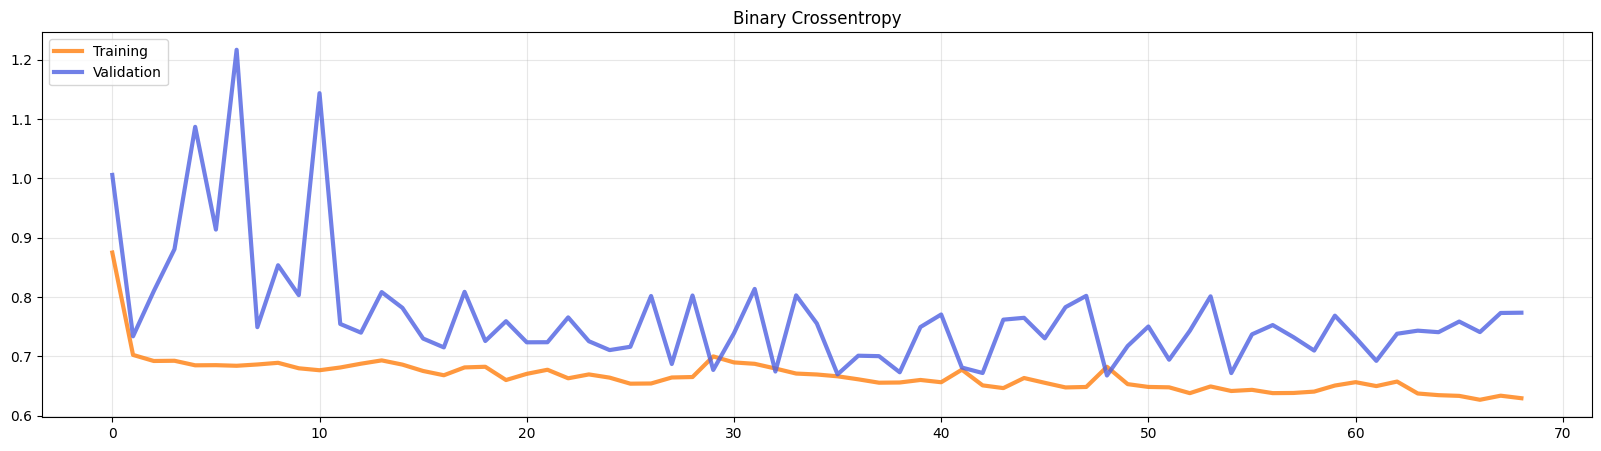

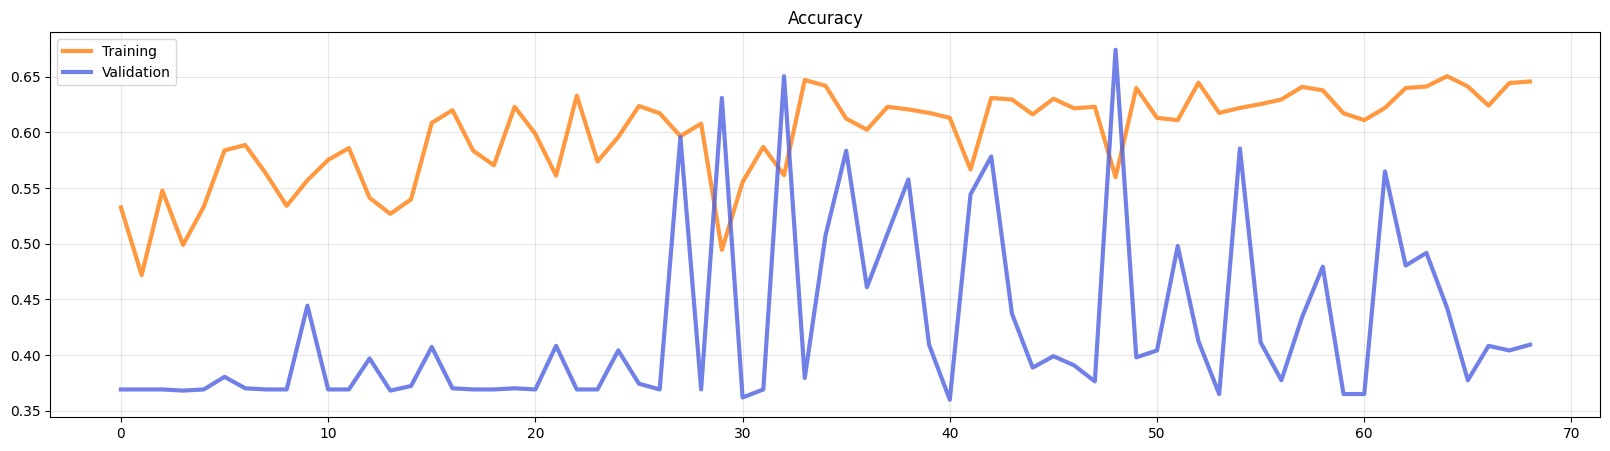

In [28]:
# Find the epoch with the highest validation accuracy
best_epoch = np.argmax(history['val_accuracy'])

# Plot training and validation performance metrics
plt.figure(figsize=(20, 5))

# Plot training and validation loss
plt.plot(history['loss'], label='Training', alpha=0.8, color='#ff7f0e', linewidth=3)
plt.plot(history['val_loss'], label='Validation', alpha=0.8, color='#4D61E2', linewidth=3)
plt.legend(loc='upper left')
plt.title('Binary Crossentropy')
plt.grid(alpha=0.3)

plt.figure(figsize=(20, 5))

# Plot training and validation accuracy, highlighting the best epoch
plt.plot(history['accuracy'], label='Training', alpha=0.8, color='#ff7f0e', linewidth=3)
plt.plot(history['val_accuracy'], label='Validation', alpha=0.8, color='#4D61E2', linewidth=3)
plt.legend(loc='upper left')
plt.title('Accuracy')
plt.grid(alpha=0.3)


plt.show()

In [29]:
del model

# Transfer learning - MobilenetV2
To get a more complex model to address possible underfitting problems in the LeNet model we use transfer learning on MobileNetV2 trained on imagenet. The technique is to import this model and remove the classification part of the network. Then we add our own classification on top of this.

After hyperparameter tuning during training we figured out that GAP along with a Dense layer and 2 dropout layers gives a good performance. In addition the dropout layers addresses overfitting problems we had early in the training stage.

In [30]:
def build_mobilenet2_tf(input_shape, learning_rate=1.e-5, dropout_rate = 0.5, seed=42, finetune=True):
    model = tf.keras.applications.MobileNetV2(input_shape=(96, 96, 3),
                                                  include_top=False,  # Do not include the top classification layer
                                                  weights='imagenet')
    model.trainable = False


    # Create an input layer
    inputs = tfk.Input(shape=input_shape)
    augmentation = build_image_augmentation_layer()(inputs)


    # Connect MobileNetV2 to the input
    x = model(augmentation)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)
    x = tf.keras.layers.Dense(1024, activation='relu')(x)  # Add a fully connected layer
    x = tf.keras.layers.Dropout(dropout_rate)(x)
    predictions = tf.keras.layers.Dense(1, activation='sigmoid')(x)  # Add a final sigmoid layer for classification

    # This is the model we will train
    model = tf.keras.Model(inputs=inputs, outputs=predictions)

    # Compile the model
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                  loss='binary_crossentropy',  # Since it's a binary classification
                  metrics=[tf.keras.metrics.AUC(), "accuracy"])

    return model

### Training MobileNetv2 transfer learning

In [31]:
model = build_mobilenet2_tf(input_shape)

early_stopping = tfk.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=20, restore_best_weights=True)
# Now you can use model.fit to train your model
history_tf = model.fit(
    x=X_train,
    y=y_train,
    batch_size=batch_size,
    epochs=epochs,
    class_weight=class_weights_dict,
    validation_data=(X_validation, y_validation),
    callbacks = [early_stopping]).history

9406464/9406464 [==============================] - 0s 0us/step
Epoch 1/200
23/23 [==============================] - 10s 150ms/step - loss: 0.9837 - auc_1: 0.5243 - accuracy: 0.5258 - val_loss: 0.6955 - val_auc_1: 0.5145 - val_accuracy: 0.5485
Epoch 2/200
23/23 [==============================] - 1s 63ms/step - loss: 1.0088 - auc_1: 0.5018 - accuracy: 0.4948 - val_loss: 0.6874 - val_auc_1: 0.5542 - val_accuracy: 0.5598
Epoch 3/200
23/23 [==============================] - 1s 64ms/step - loss: 0.9533 - auc_1: 0.5294 - accuracy: 0.5179 - val_loss: 0.6638 - val_auc_1: 0.5893 - val_accuracy: 0.5897
Epoch 4/200
23/23 [==============================] - 2s 68ms/step - loss: 0.9064 - auc_1: 0.5582 - accuracy: 0.5450 - val_loss: 0.6544 - val_auc_1: 0.6160 - val_accuracy: 0.6072
Epoch 5/200
23/23 [==============================] - 2s 72ms/step - loss: 0.8909 - auc_1: 0.5667 - accuracy: 0.5409 - val_loss: 0.6427 - val_auc_1: 0.6399 - val_accuracy: 0.6237
Epoch 6/200
23/23 [==========================

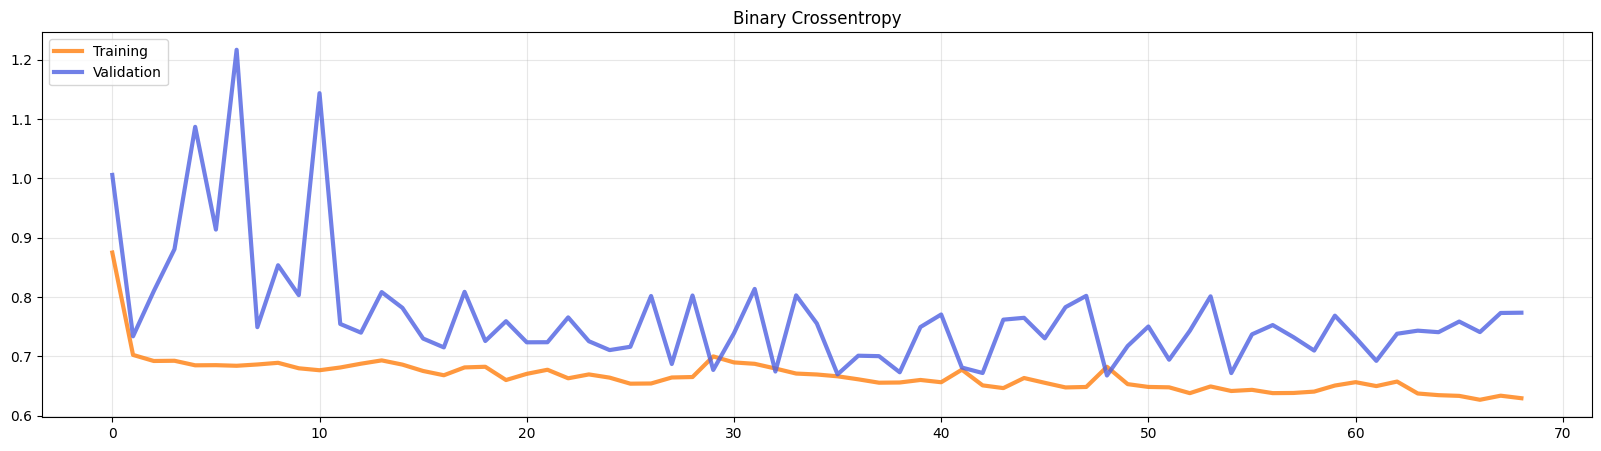

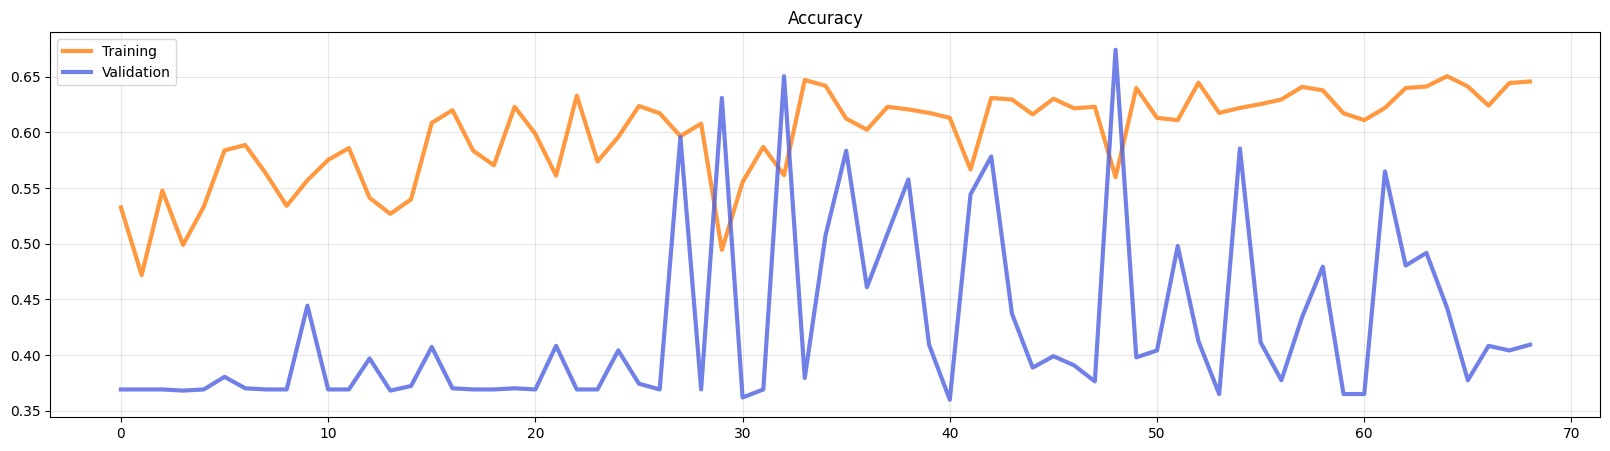

In [32]:
# NB: this plots `history` (LeNet), not `history_tf`
# Find the epoch with the highest validation accuracy
best_epoch = np.argmax(history['val_accuracy'])

# Plot training and validation performance metrics
plt.figure(figsize=(20, 5))

# Plot training and validation loss
plt.plot(history['loss'], label='Training', alpha=0.8, color='#ff7f0e', linewidth=3)
plt.plot(history['val_loss'], label='Validation', alpha=0.8, color='#4D61E2', linewidth=3)
plt.legend(loc='upper left')
plt.title('Binary Crossentropy')
plt.grid(alpha=0.3)

plt.figure(figsize=(20, 5))

# Plot training and validation accuracy, highlighting the best epoch
plt.plot(history['accuracy'], label='Training', alpha=0.8, color='#ff7f0e', linewidth=3)
plt.plot(history['val_accuracy'], label='Validation', alpha=0.8, color='#4D61E2', linewidth=3)
plt.legend(loc='upper left')
plt.title('Accuracy')
plt.grid(alpha=0.3)


plt.show()

In [33]:
del model

# MobilenetV2 - Finetuned
Since the models we are using are trained on classical classification of thousands of classes of images, we do not suspect that it is detailed enough to be trained on classifying if plants are healthy or unhealthy. To make it more fine tuned to our use case. We could fine tune the models. This is done by training the model using a very low learning rate

In [34]:
def build_mobilenet2_gap_finetuned(input_shape, learning_rate=1.e-5, dropout_rate = 0.5, seed=42):
    model = tf.keras.applications.MobileNetV2(input_shape=(96, 96, 3),
                                                  include_top=False,  # Do not include the top classification layer
                                                  weights='imagenet')
    # Freeze the base model
    model.trainable = True

    # Fine-tune from this layer onwards
    fine_tune_at = 100

    # Freeze all the layers before the `fine_tune_at` layer
    for layer in model.layers[:fine_tune_at]:
      layer.trainable = False

    # Create an input layer
    inputs = tfk.Input(shape=input_shape, name="Inputs")
    augmentation = build_image_augmentation_layer()(inputs)


    # Connect MobileNetV2 to the input
    x = model(augmentation)
    x = tf.keras.layers.GlobalAveragePooling2D(name="GAP")(x)
    x = tf.keras.layers.Dropout(dropout_rate, name="Dropout1")(x)
    x = tf.keras.layers.Dense(1024, activation='relu', name="Dense1")(x)  # Add a fully connected layer
    x = tf.keras.layers.Dropout(dropout_rate, name="Dropout2")(x)
    predictions = tf.keras.layers.Dense(1, activation='sigmoid', name="Output")(x)  # Add a final sigmoid layer for classification

    # This is the model we will train
    model = tf.keras.Model(inputs=inputs, outputs=predictions)

    # Compile the model
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                  loss='binary_crossentropy',  # Since it's a binary classification
                  metrics=[tf.keras.metrics.AUC(), "accuracy"])

    return model

In [55]:
model = build_mobilenet2_gap_finetuned(input_shape)

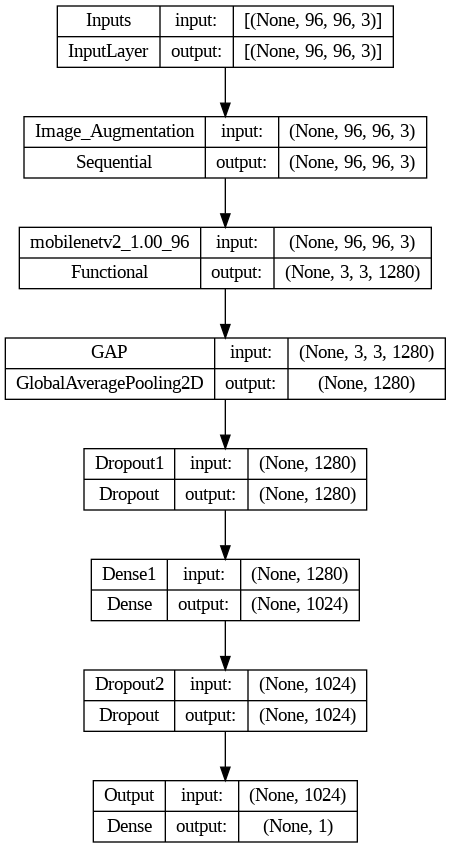

In [56]:
tf.keras.utils.plot_model(model, show_shapes=True, show_layer_names=True)

### Training MobileNetv2 finetuned

In [57]:
early_stopping = tfk.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=20, restore_best_weights=True)
# Now you can use model.fit to train your model
batch_size = 32
history_ft = model.fit(
    x=X_train,
    y=y_train,
    batch_size=batch_size,
    epochs=epochs,
    class_weight=class_weights_dict,
    validation_data=(X_validation, y_validation),
    callbacks = [early_stopping]).history

Epoch 1/200
91/91 [==============================] - 21s 103ms/step - loss: 0.9246 - auc_3: 0.4968 - accuracy: 0.4828 - val_loss: 0.6746 - val_auc_3: 0.5698 - val_accuracy: 0.6247
Epoch 2/200
91/91 [==============================] - 4s 41ms/step - loss: 0.8396 - auc_3: 0.5578 - accuracy: 0.5371 - val_loss: 0.6578 - val_auc_3: 0.6234 - val_accuracy: 0.6454
Epoch 3/200
91/91 [==============================] - 4s 44ms/step - loss: 0.8084 - auc_3: 0.5914 - accuracy: 0.5639 - val_loss: 0.6516 - val_auc_3: 0.6711 - val_accuracy: 0.6649
Epoch 4/200
91/91 [==============================] - 5s 54ms/step - loss: 0.7811 - auc_3: 0.6205 - accuracy: 0.5859 - val_loss: 0.6156 - val_auc_3: 0.7123 - val_accuracy: 0.6876
Epoch 5/200
91/91 [==============================] - 6s 71ms/step - loss: 0.7682 - auc_3: 0.6315 - accuracy: 0.5804 - val_loss: 0.6077 - val_auc_3: 0.7375 - val_accuracy: 0.6907
Epoch 6/200
91/91 [==============================] - 5s 52ms/step - loss: 0.7267 - auc_3: 0.6725 - accuracy:

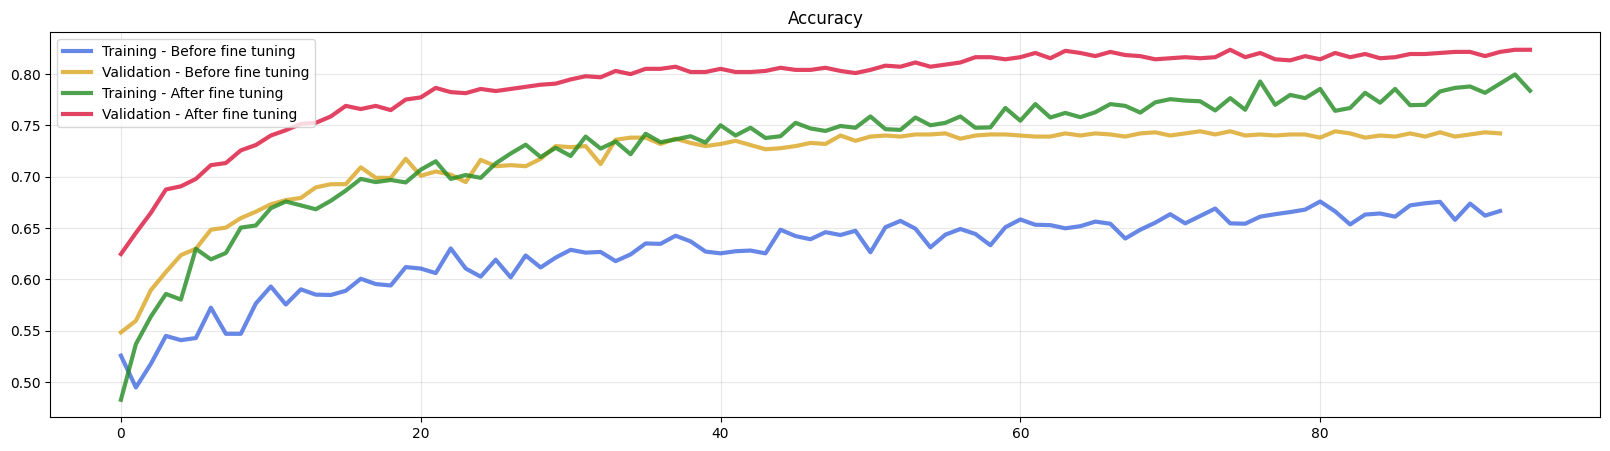

In [58]:
plt.figure(figsize=(20, 5))

# Plot training and validation accuracy, highlighting the best epoch
plt.plot(history_tf['accuracy'], label='Training - Before fine tuning', alpha=0.8, color='#4169e1', linewidth=3)
plt.plot(history_tf['val_accuracy'], label='Validation - Before fine tuning', alpha=0.8, color='#daa520', linewidth=3)
plt.legend(loc='upper left')
plt.title('Accuracy')
plt.grid(alpha=0.3)

# Plot training and validation accuracy, highlighting the best epoch
plt.plot(history_ft['accuracy'], label='Training - After fine tuning', alpha=0.8, color='#228b22', linewidth=3)
plt.plot(history_ft['val_accuracy'], label='Validation - After fine tuning', alpha=0.8, color='#dc143c', linewidth=3)
plt.legend(loc='upper left')
plt.title('Accuracy')
plt.grid(alpha=0.3)

plt.show()

### Saving Mobilenetv2 finetuned

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [44]:
model.save('/content/drive/MyDrive/Colab Notebooks/RedstoneRookies/mobilenet2_finetuned.h5')

In [45]:
del model

# Evaluating model performance

From the training we choose the most promising model. Mobilenet2 finetuned.

In [46]:
model = tfk.models.load_model('/content/drive/MyDrive/Colab Notebooks/RedstoneRookies/mobilenet2_finetuned.h5')

## Checking accuracy on validation set
Firstly, we would like to check what the best thresholds in the probabilities given by the model to give the model. This is done by a simple linear search.

In [59]:
best_accuracy = 0
best_threshold = 0
i = 0
while i < 1:
  i += 0.01
  threshold = i

  # Predict labels for the entire test set
  predictions = model.predict(X_validation, verbose=0)
  predictions_probs = np.hstack([(predictions <= threshold).astype(int), (predictions > threshold).astype(int)])

  binary_predictions = tf.argmax(predictions_probs, axis=1)

  # Compute classification metrics
  accuracy = accuracy_score(y_validation, binary_predictions)

  if accuracy > best_accuracy:
    print(f"Threshold: {threshold} increased accuracy to {accuracy}")
    best_accuracy = accuracy
    best_threshold = threshold

  del predictions
  del predictions_probs

print(f"FINAL SOLUTION: Threshold: {best_threshold} is the best with accuracy: {best_accuracy}")

Threshold: 0.01 increased accuracy to 0.6371134020618556
Threshold: 0.02 increased accuracy to 0.6505154639175258
Threshold: 0.03 increased accuracy to 0.6597938144329897
Threshold: 0.04 increased accuracy to 0.6659793814432989
Threshold: 0.05 increased accuracy to 0.6752577319587629


KeyboardInterrupt: ignored

As we see 0.5 is the best threshold for the model. This will be used going forward.

(The search above was interrupted at 0.05. The report says 0.5 was still the best threshold.)

In [60]:
threshold = 0.5

# Predict labels for the entire test set
predictions = model.predict(X_validation, verbose=0)
predictions_probs = np.hstack([(predictions <= threshold).astype(int), (predictions > threshold).astype(int)])

binary_predictions = tf.argmax(predictions_probs, axis=1)

# Display the shape of the predictions
print("Predictions Shape:", binary_predictions.shape)

Predictions Shape: (970,)


Accuracy: 0.8237
Precision: 0.8218
Recall: 0.7925
F1: 0.8026


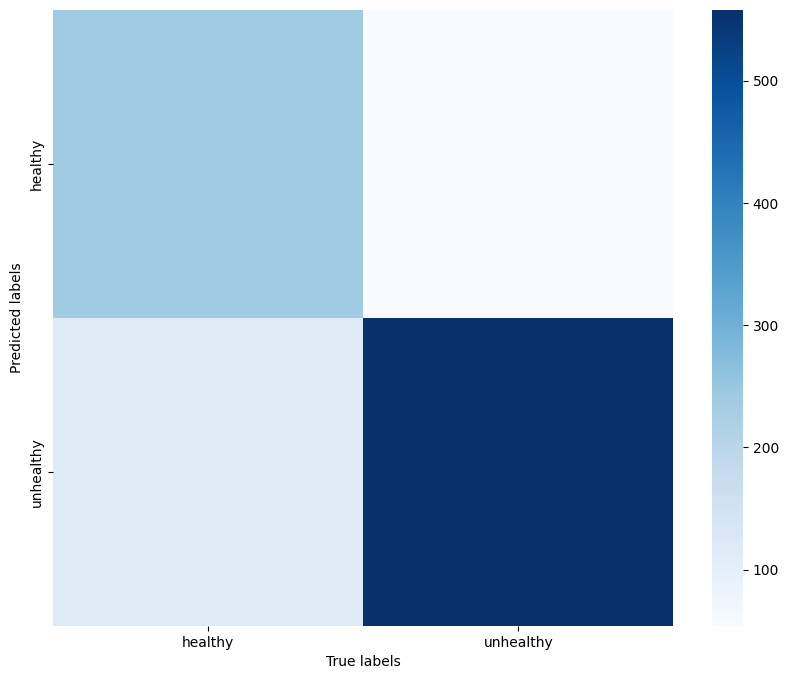

In [61]:
# Compute the confusion matrix
cm = confusion_matrix(y_validation, binary_predictions)

# Compute classification metrics
accuracy = accuracy_score(y_validation, binary_predictions)
precision = precision_score(y_validation, binary_predictions, average='macro')
recall = recall_score(y_validation, binary_predictions, average='macro')
f1 = f1_score(y_validation, binary_predictions, average='macro')

# Display the computed metri
print('Accuracy:', accuracy.round(4))
print('Precision:', precision.round(4))
print('Recall:', recall.round(4))
print('F1:', f1.round(4))

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm.T, xticklabels=list(('healthy','unhealthy')), yticklabels=list(('healthy','unhealthy')), cmap='Blues')
plt.xlabel('True labels')
plt.ylabel('Predicted labels')
plt.show()

To check if there is any images which are not of plants which we might have missed, we plot all the images where the model is uncertain (around the value 0.5).

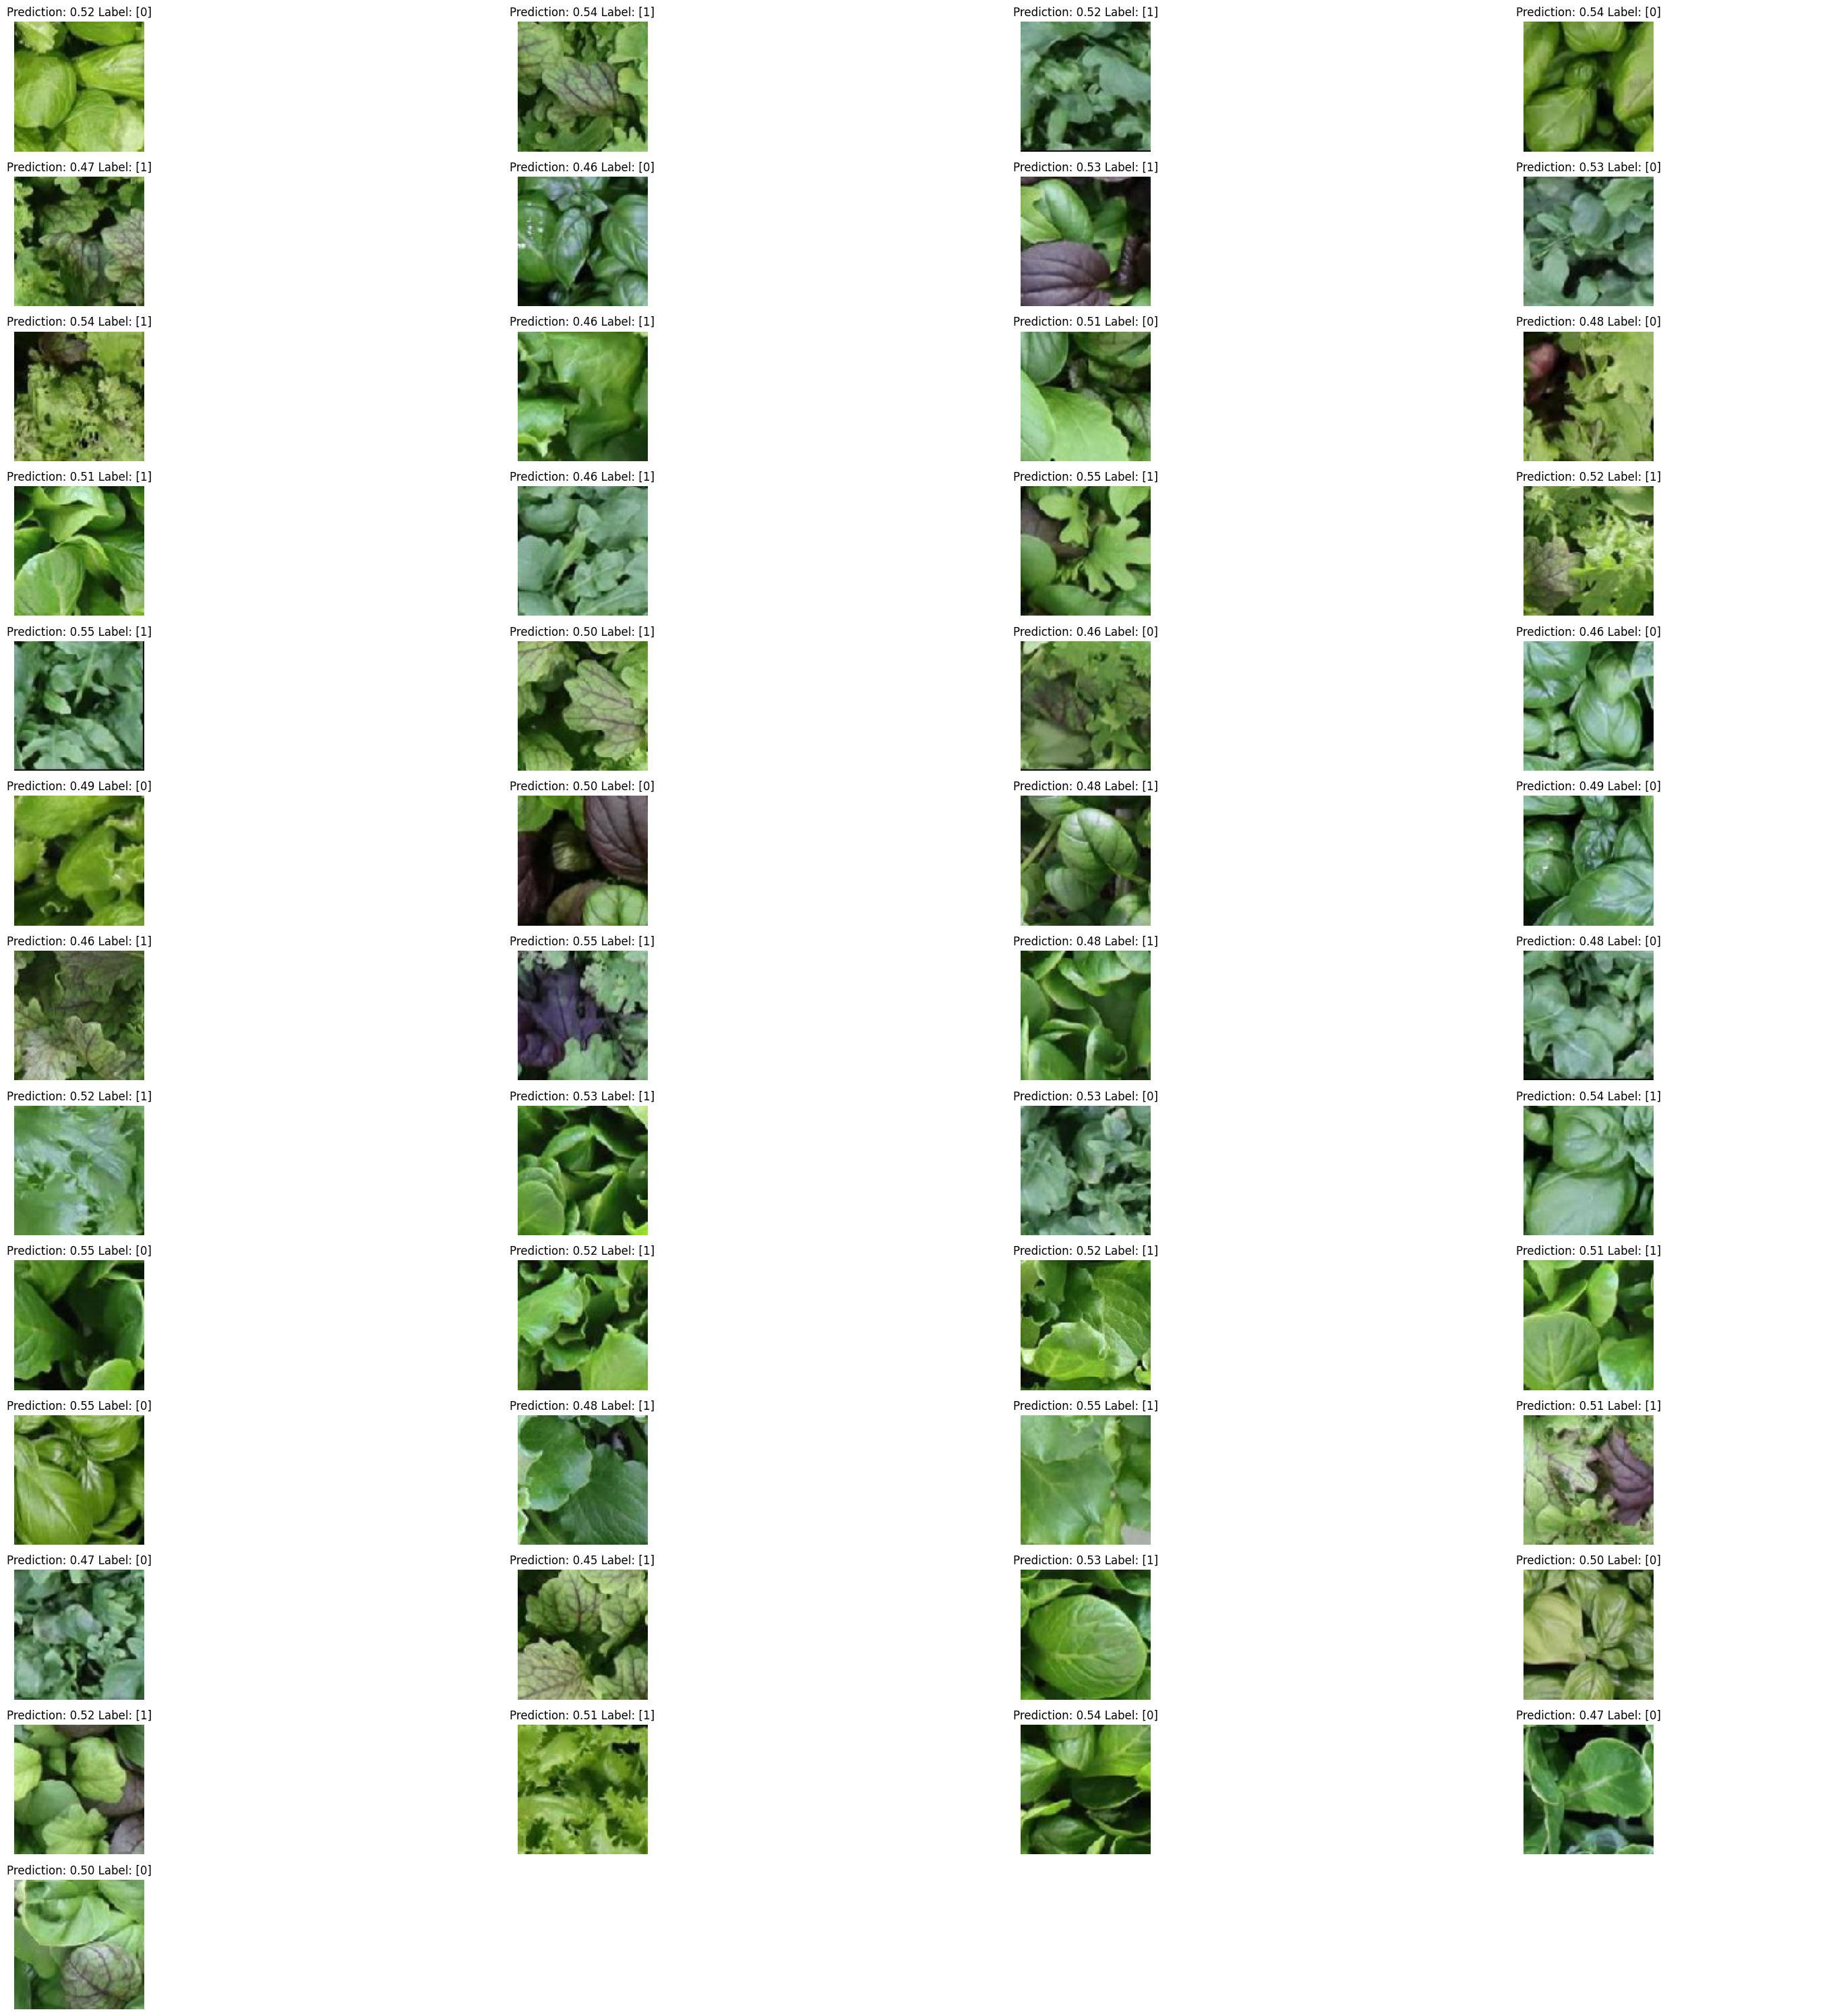

In [50]:
def plot_unsure_predictions(predictions, images, labels):
  # Define the range for which you want to plot images
  lower_bound = 0.45
  upper_bound = 0.55

  # Identify indices of predictions in the desired range
  selected_indices = np.where((predictions >= lower_bound) & (predictions <= upper_bound))[0]

  # Retrieve the corresponding images based on the selected indices
  selected_images = [images[i] for i in selected_indices]  # Replace 'your_images' with your actual image data

  # Set the number of columns and rows in the grid
  num_columns = 4
  num_rows = len(selected_images) // num_columns + int(len(selected_images) % num_columns != 0)

  # Create a scrollable grid
  fig, axes = plt.subplots(num_rows, num_columns, figsize=(30, 30))

  # Flatten the axes array in case there's only one row or column
  axes = axes.flatten()

  for ax, image, prediction, indice in zip(axes, selected_images, predictions[selected_indices], selected_indices):
      if ax is not None:
          ax.imshow(image)  # Replace 'image' with your actual image data
          ax.set_title(f'Prediction: {prediction[0]:.2f} Label: {labels[indice]}')
          ax.axis('off')

  # Hide any empty subplots
  for i in range(len(selected_images), len(axes)):
      axes[i].axis('off')

  plt.tight_layout()
  plt.show()

plot_unsure_predictions(predictions, X_validation, y_validation)

As we see there is no invalid images for these uncertain predictions

## Testing the model on the test set

In [62]:
threshold = 0.5

# Predict labels for the entire test set
predictions = model.predict(X_test, verbose=0)
predictions_probs = np.hstack([(predictions <= threshold).astype(int), (predictions > threshold).astype(int)])

binary_predictions = tf.argmax(predictions_probs, axis=1)

# Display the shape of the predictions
print("Predictions Shape:", binary_predictions.shape)

Predictions Shape: (970,)


Accuracy: 0.8082
Precision: 0.8061
Recall: 0.7733
F1: 0.7838


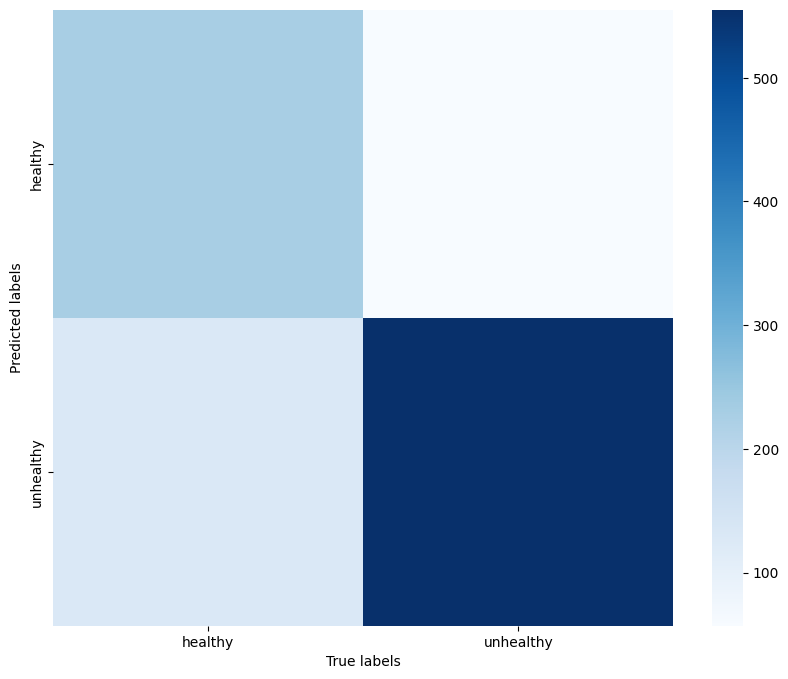

[[229 129]
 [ 57 555]]


In [63]:
# Compute the confusion matrix
cm = confusion_matrix(y_test, binary_predictions)

# Compute classification metrics
accuracy = accuracy_score(y_test, binary_predictions)
precision = precision_score(y_test, binary_predictions, average='macro')
recall = recall_score(y_test, binary_predictions, average='macro')
f1 = f1_score(y_test, binary_predictions, average='macro')

# Display the computed metrics
print('Accuracy:', accuracy.round(4))
print('Precision:', precision.round(4))
print('Recall:', recall.round(4))
print('F1:', f1.round(4))

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm.T, xticklabels=list(('healthy','unhealthy')), yticklabels=list(('healthy','unhealthy')), cmap='Blues')
plt.xlabel('True labels')
plt.ylabel('Predicted labels')
plt.show()

print(cm)

# Absolute final model
Train on ALL data for submission

In [64]:
# Split data into only validation and training for final model sub (submission)
X_train_sub, X_val_sub, y_train_sub, y_val_sub = train_test_split(
    X_final,
    y_encoded,
    test_size = 0.15,
    random_state=seed,
    stratify=y_encoded # stratify to have even distribution of classes in the splits
)

In [65]:
model_final = build_mobilenet2_gap_finetuned(input_shape)

batch_size = 32
model_final_history = model_final.fit(
    x=X_train_sub,
    y=y_train_sub,
    batch_size=batch_size,
    epochs=epochs,
    class_weight=class_weights_dict,
    validation_data=(X_val_sub, y_val_sub),
    callbacks = [early_stopping]).history

Epoch 1/200
129/129 [==============================] - 17s 56ms/step - loss: 0.8838 - auc_4: 0.5410 - accuracy: 0.5170 - val_loss: 0.7559 - val_auc_4: 0.6096 - val_accuracy: 0.5069
Epoch 2/200
129/129 [==============================] - 4s 30ms/step - loss: 0.8268 - auc_4: 0.5756 - accuracy: 0.5556 - val_loss: 0.6640 - val_auc_4: 0.6747 - val_accuracy: 0.6099
Epoch 3/200
129/129 [==============================] - 4s 30ms/step - loss: 0.7859 - auc_4: 0.6143 - accuracy: 0.5803 - val_loss: 0.6063 - val_auc_4: 0.7185 - val_accuracy: 0.6580
Epoch 4/200
129/129 [==============================] - 4s 33ms/step - loss: 0.7463 - auc_4: 0.6470 - accuracy: 0.6004 - val_loss: 0.5726 - val_auc_4: 0.7595 - val_accuracy: 0.7074
Epoch 5/200
129/129 [==============================] - 4s 34ms/step - loss: 0.7260 - auc_4: 0.6682 - accuracy: 0.6189 - val_loss: 0.5379 - val_auc_4: 0.7807 - val_accuracy: 0.7294
Epoch 6/200
129/129 [==============================] - 4s 30ms/step - loss: 0.7169 - auc_4: 0.6811 

Predictions Shape: (728,)
Accuracy: 0.8283
Precision: 0.8217
Recall: 0.8038
F1: 0.8109


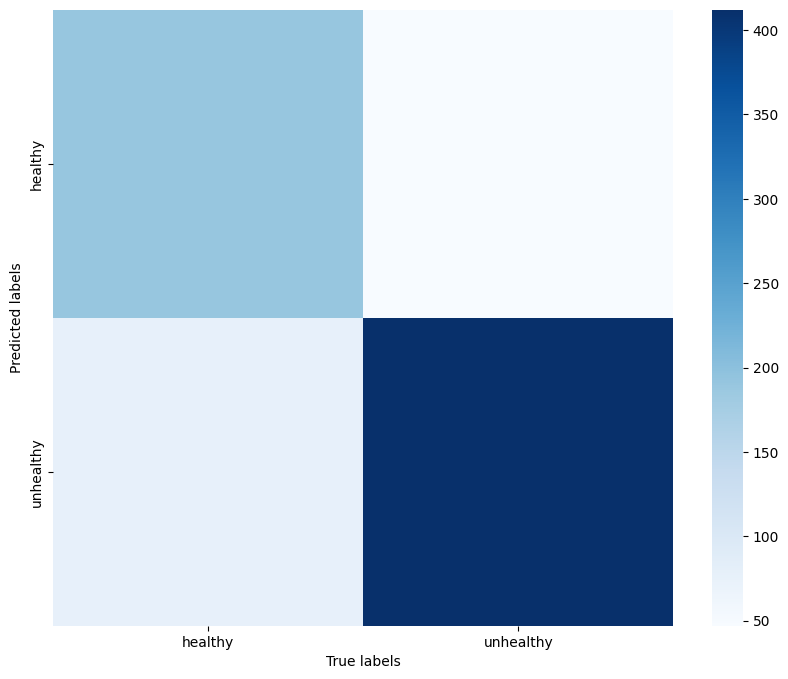

In [66]:
threshold = 0.5

# Predict labels for the entire test set
predictions = model_final.predict(X_val_sub, verbose=0)
predictions_probs = np.hstack([(predictions <= threshold).astype(int), (predictions > threshold).astype(int)])

binary_predictions = tf.argmax(predictions_probs, axis=1)

# Display the shape of the predictions
print("Predictions Shape:", binary_predictions.shape)

# Compute the confusion matrix
cm = confusion_matrix(y_val_sub, binary_predictions)

# Compute classification metrics
accuracy = accuracy_score(y_val_sub, binary_predictions)
precision = precision_score(y_val_sub, binary_predictions, average='macro')
recall = recall_score(y_val_sub, binary_predictions, average='macro')
f1 = f1_score(y_val_sub, binary_predictions, average='macro')

# Display the computed metri
print('Accuracy:', accuracy.round(4))
print('Precision:', precision.round(4))
print('Recall:', recall.round(4))
print('F1:', f1.round(4))

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm.T, xticklabels=list(('healthy','unhealthy')), yticklabels=list(('healthy','unhealthy')), cmap='Blues')
plt.xlabel('True labels')
plt.ylabel('Predicted labels')
plt.show()

In [67]:
model_final.save('/content/drive/MyDrive/Colab Notebooks/RedstoneRookies/mobilenetv2_finalsubmission.h5')
del model_final